  Ligand Pd Complex  Yield  Substrate
0     L1         C1    9.0          1
1     L2         C1   47.0          1
2     L3         C1   70.0          1
3     L4         C1   45.0          1
4     L5         C1    8.0          1
Index(['Ligand', 'Pd Complex', 'Yield', 'Substrate'], dtype='object')


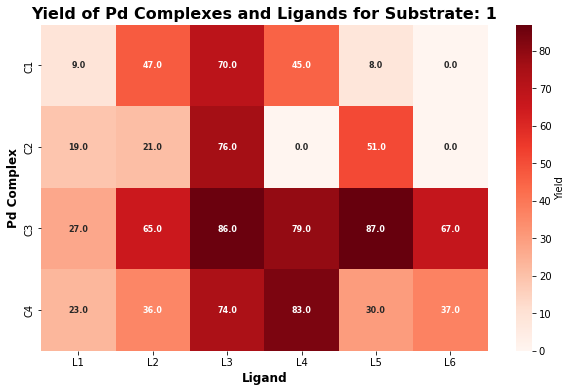

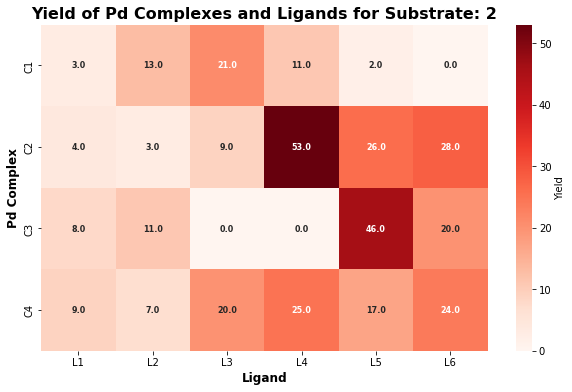

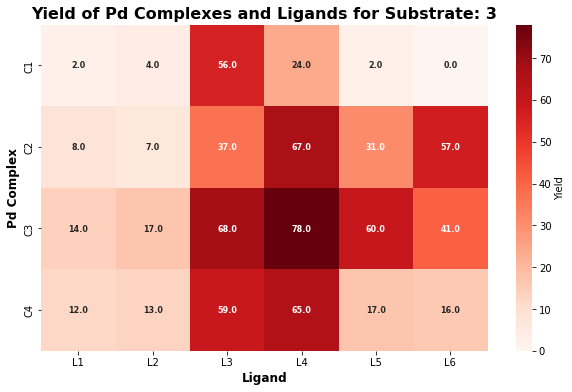

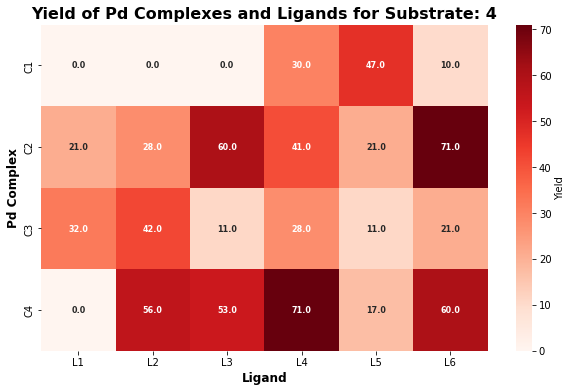

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the Excel file
file_path = 'Pd_HTE.xlsx'  # Adjust to your file path
df = pd.read_excel(file_path)

# Check the structure of the DataFrame
print(df.head())
print(df.columns)

# Get the unique substrates
substrates = df['Substrate'].unique()

# Create a plot for each substrate
for substrate in substrates:
    substrate_data = df[df['Substrate'] == substrate]
    
    # Create a pivot table for the heatmap
    heatmap_data = substrate_data.pivot_table(
        index='Pd Complex',  # Y-axis
        columns='Ligand',  # X-axis
        values='Yield',  # The values to display in the heatmap
        aggfunc='mean'  # Aggregate function if needed
    ).fillna(0)  # Fill missing values with 0

    # Plot the heatmap
    plt.figure(figsize=(10, 6))
    sns.heatmap(heatmap_data, annot=True, fmt='.1f', cmap='Reds', 
                annot_kws={'weight': 'bold', 'size': 8}, cbar_kws={'label': 'Yield'})

    # Title and labels
    plt.title(f"Yield of Pd Complexes and Ligands for Substrate: {substrate}", weight='bold', fontsize=16)
    plt.xlabel("Ligand", weight='bold', fontsize=12)
    plt.ylabel("Pd Complex", weight='bold', fontsize=12)

    # Save the figure as a high-resolution image
    plt.savefig(f'yield_heatmap_{substrate}.png', dpi=500, bbox_inches='tight')
    plt.show()


  Ligand Pd Complex  Yield  Substrate
0     L1         C1    9.0          1
1     L2         C1   47.0          1
2     L3         C1   70.0          1
3     L4         C1   45.0          1
4     L5         C1    8.0          1
Index(['Ligand', 'Pd Complex', 'Yield', 'Substrate'], dtype='object')


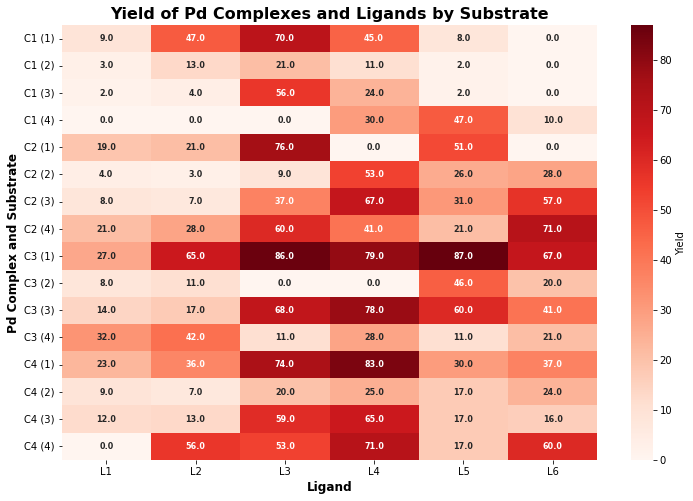

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the Excel file
file_path = 'Pd_HTE.xlsx'  # Adjust to your file path
df = pd.read_excel(file_path)

# Ensure the structure of the DataFrame is as expected
print(df.head())
print(df.columns)

# Convert Pd Complex and Substrate to string to avoid type issues
df['Pd Complex'] = df['Pd Complex'].astype(str)
df['Substrate'] = df['Substrate'].astype(str)

# Create a new column that combines Pd Complex with Substrate
df['Complex_Substrate'] = df['Pd Complex'] + ' (' + df['Substrate'] + ')'

# Create a pivot table with Complex and Substrate
heatmap_data = df.pivot_table(
    index='Complex_Substrate',  # Y-axis with combined complexity and substrate
    columns='Ligand',  # X-axis for Ligands
    values='Yield',  # The values to display in the heatmap
    aggfunc='mean'  # Aggregate function if needed
).fillna(0)  # Fill missing values with 0

# Plot the heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, annot=True, fmt='.1f', cmap='Reds', 
            annot_kws={'weight': 'bold', 'size': 8}, cbar_kws={'label': 'Yield'})

# Title and labels
plt.title("Yield of Pd Complexes and Ligands by Substrate", weight='bold', fontsize=16)
plt.xlabel("Ligand", weight='bold', fontsize=12)
plt.ylabel("Pd Complex and Substrate", weight='bold', fontsize=12)

# Save the figure as a high-resolution image
plt.savefig('combined_yield_heatmap_with_complexes.png', dpi=500, bbox_inches='tight')
plt.show()


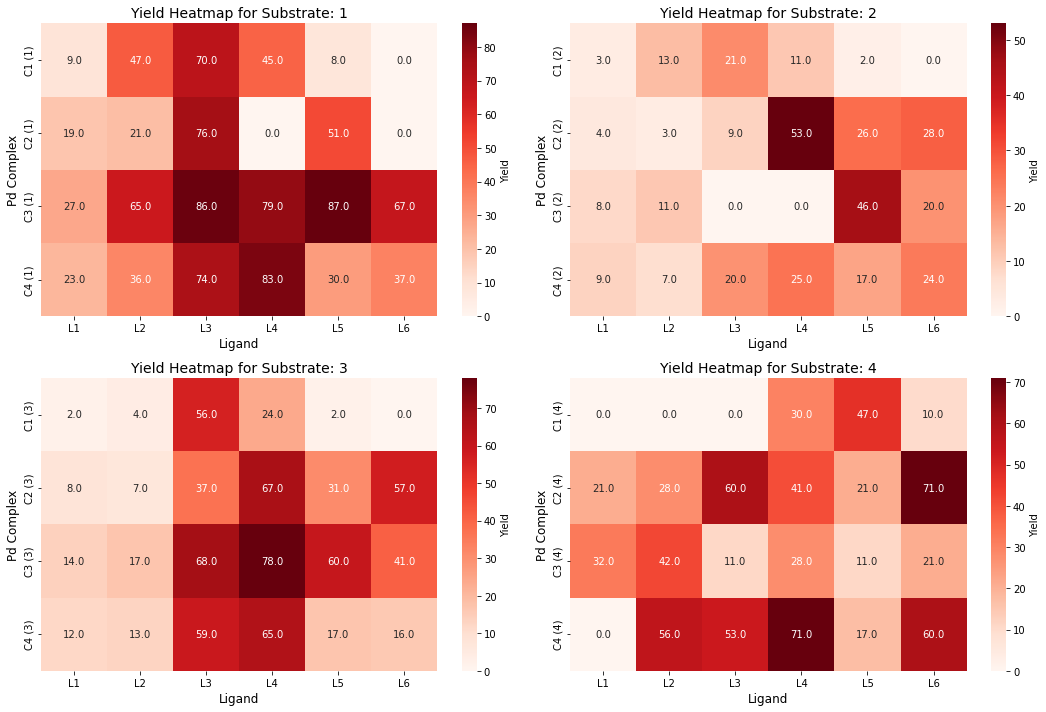

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the Excel file
file_path = 'Pd_HTE.xlsx'  # Adjust to your file path
df = pd.read_excel(file_path)

# Convert necessary columns to string
df['Pd Complex'] = df['Pd Complex'].astype(str)
df['Substrate'] = df['Substrate'].astype(str)

# Create a new column that combines Pd Complex with Substrate
df['Complex_Substrate'] = df['Pd Complex'] + ' (' + df['Substrate'] + ')'

# Create a list of unique substrates
substrates = df['Substrate'].unique()

# Number of columns for the subplot grid
n_cols = 2  # Adjust as needed
n_rows = (len(substrates) + n_cols - 1) // n_cols  # Calculate number of rows needed

# Set up the subplot grid
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 5))
axes = axes.flatten()  # Flatten the axes array for easy indexing

for i, substrate in enumerate(substrates):
    # Filter data for the current substrate
    substrate_data = df[df['Substrate'] == substrate]
    
    # Create a pivot table for the heatmap
    heatmap_data = substrate_data.pivot_table(
        index='Complex_Substrate', 
        columns='Ligand', 
        values='Yield', 
        aggfunc='mean'
    ).fillna(0)  # Fill missing values with 0
    
    # Plot the heatmap
    sns.heatmap(heatmap_data, ax=axes[i], annot=True, fmt='.1f', cmap='Reds', 
                cbar_kws={'label': 'Yield'})
    
    # Title for each subplot
    axes[i].set_title(f'Yield Heatmap for Substrate: {substrate}', fontsize=14)
    axes[i].set_xlabel('Ligand', fontsize=12)
    axes[i].set_ylabel('Pd Complex', fontsize=12)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.savefig('yield_heatmap_by_substrate.png', dpi=500, bbox_inches='tight')
plt.show()


  Ligand Pd Complex  Yield  Substrate
0     L1         C1    9.0          1
1     L2         C1   47.0          1
2     L3         C1   70.0          1
3     L4         C1   45.0          1
4     L5         C1    8.0          1
Index(['Ligand', 'Pd Complex', 'Yield', 'Substrate'], dtype='object')


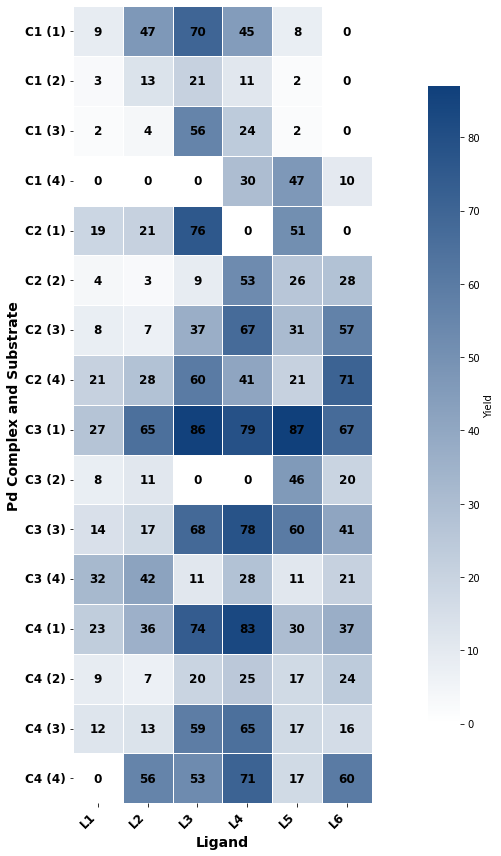

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Load the Excel file
file_path = 'Pd_HTE.xlsx'  # Adjust to your file path
df = pd.read_excel(file_path)

# Ensure the structure of the DataFrame is as expected
print(df.head())
print(df.columns)

# Convert Pd Complex and Substrate to string to avoid type issues
df['Pd Complex'] = df['Pd Complex'].astype(str)
df['Substrate'] = df['Substrate'].astype(str)

# Create a new column that combines Pd Complex with Substrate
df['Complex_Substrate'] = df['Pd Complex'] + ' (' + df['Substrate'] + ')'

# Create a pivot table with Complex and Substrate
heatmap_data = df.pivot_table(
    index='Complex_Substrate',  # Y-axis with combined complexity and substrate
    columns='Ligand',  # X-axis for Ligands
    values='Yield',  # The values to display in the heatmap
    aggfunc='mean'  # Aggregate function if needed
).fillna(0)  # Fill missing values with 0

# Create a custom color map using the provided color code #10407B
custom_color_map = mcolors.LinearSegmentedColormap.from_list(
    'custom_blue', ['#FFFFFF', '#10407B'], N=256)  # From white to your color

# Set a larger figure size for better clarity
plt.figure(figsize=(16, 12))

# Create a heatmap with the custom color map and improved styling
sns.heatmap(
    heatmap_data,
    annot=True,  # Show values inside the cells
    fmt='g',  # Use 'g' format to display numbers as integers (e.g., 21 instead of 21.0)
    cmap=custom_color_map,  # Apply the custom color map with your color code
    annot_kws={'weight': 'bold', 'size': 12, 'color': 'black'},  # Bold and larger annotation size
    cbar_kws={'label': 'Yield', 'shrink': 0.8},  # Shrink the color bar a bit to make it fit
    linewidths=0.5,  # Add some separation between cells
    linecolor='white',  # Set the line color between cells to white
    square=True,  # Make the heatmap square-shaped for symmetry
    cbar=True,  # Show color bar
)

# Axis labels with improved font size and boldness
plt.xlabel("Ligand", weight='bold', fontsize=14)
plt.ylabel("Pd Complex and Substrate", weight='bold', fontsize=14)

# Rotate the x-axis labels to prevent overlap and make them more readable
plt.xticks(rotation=45, ha='right', fontsize=12, weight='bold')
plt.yticks(rotation=0, fontsize=12, weight='bold')  # Keep y-axis labels horizontal (no italics)

# Adjust layout to prevent clipping of labels
plt.tight_layout()

# Save the figure as a high-resolution image
plt.savefig('custom_blue_heatmap_10407B.png', dpi=500, bbox_inches='tight')

# Show the plot
plt.show()


  Ligand Pd Complex  Yield  Substrate
0     L1         C1    9.0          1
1     L2         C1   47.0          1
2     L3         C1   70.0          1
3     L4         C1   45.0          1
4     L5         C1    8.0          1
Index(['Ligand', 'Pd Complex', 'Yield', 'Substrate'], dtype='object')


/tmp/ipykernel_400535/2531321248.py:55: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


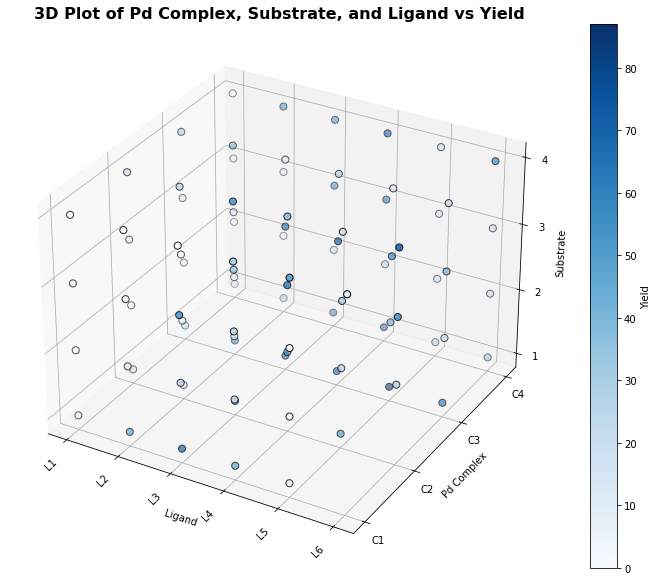

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Load the Excel file
file_path = 'Pd_HTE.xlsx'  # Adjust to your file path
df = pd.read_excel(file_path)

# Ensure the structure of the DataFrame is as expected
print(df.head())
print(df.columns)

# Convert Pd Complex, Substrate, and Ligand to string to avoid type issues
df['Pd Complex'] = df['Pd Complex'].astype(str)
df['Substrate'] = df['Substrate'].astype(str)
df['Ligand'] = df['Ligand'].astype(str)

# Create a figure for the 3D plot
fig = plt.figure(figsize=(14, 10))
ax = fig.add_subplot(111, projection='3d')

# Create a mapping for Pd Complex, Substrate, and Ligand to integers for 3D plotting
pd_complex_labels = {label: idx for idx, label in enumerate(df['Pd Complex'].unique())}
substrate_labels = {label: idx for idx, label in enumerate(df['Substrate'].unique())}
ligand_labels = {label: idx for idx, label in enumerate(df['Ligand'].unique())}

# Map the data in the DataFrame to integers
df['Pd Complex ID'] = df['Pd Complex'].map(pd_complex_labels)
df['Substrate ID'] = df['Substrate'].map(substrate_labels)
df['Ligand ID'] = df['Ligand'].map(ligand_labels)

# Plotting 3D scatter plot
scatter = ax.scatter(df['Ligand ID'], df['Pd Complex ID'], df['Substrate ID'], 
                     c=df['Yield'], cmap='Blues', s=50, edgecolors='k')

# Labels and title
ax.set_xlabel('Ligand')
ax.set_ylabel('Pd Complex')
ax.set_zlabel('Substrate')

# Set the ticks for each axis based on the original labels
ax.set_xticks(list(ligand_labels.values()))
ax.set_xticklabels(list(ligand_labels.keys()), rotation=45, ha='right', fontsize=10)
ax.set_yticks(list(pd_complex_labels.values()))
ax.set_yticklabels(list(pd_complex_labels.keys()), fontsize=10)
ax.set_zticks(list(substrate_labels.values()))
ax.set_zticklabels(list(substrate_labels.keys()), fontsize=10)

# Add color bar to show the Yield values
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Yield')

# Set title and display
ax.set_title('3D Plot of Pd Complex, Substrate, and Ligand vs Yield', fontsize=16, weight='bold')
plt.tight_layout()
plt.show()


  Ligand Pd Complex  Yield  Substrate
0     L1         C1    9.0          1
1     L2         C1   47.0          1
2     L3         C1   70.0          1
3     L4         C1   45.0          1
4     L5         C1    8.0          1
Index(['Ligand', 'Pd Complex', 'Yield', 'Substrate'], dtype='object')


/tmp/ipykernel_400535/2791919475.py:71: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


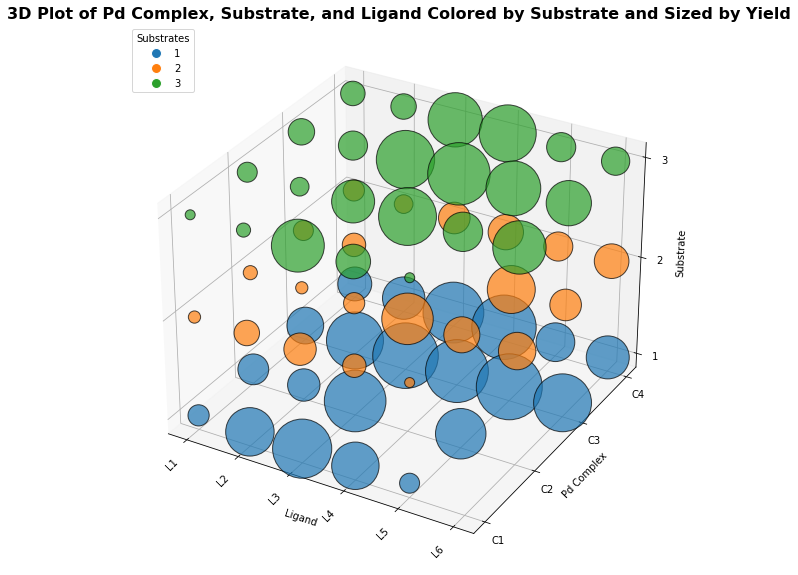

<Figure size 432x288 with 0 Axes>

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.colors as mcolors

# Load the Excel file
file_path = 'Pd_HTE_1.xlsx'  # Adjust to your file path
df = pd.read_excel(file_path)

# Ensure the structure of the DataFrame is as expected
print(df.head())
print(df.columns)

# Convert Pd Complex, Substrate, and Ligand to string to avoid type issues
df['Pd Complex'] = df['Pd Complex'].astype(str)
df['Substrate'] = df['Substrate'].astype(str)
df['Ligand'] = df['Ligand'].astype(str)

# Create a figure for the 3D plot
fig = plt.figure(figsize=(14, 10))
ax = fig.add_subplot(111, projection='3d')

# Create a mapping for Pd Complex, Substrate, and Ligand to integers for 3D plotting
pd_complex_labels = {label: idx for idx, label in enumerate(df['Pd Complex'].unique())}
substrate_labels = {label: idx for idx, label in enumerate(df['Substrate'].unique())}
ligand_labels = {label: idx for idx, label in enumerate(df['Ligand'].unique())}

# Map the data in the DataFrame to integers
df['Pd Complex ID'] = df['Pd Complex'].map(pd_complex_labels)
df['Substrate ID'] = df['Substrate'].map(substrate_labels)
df['Ligand ID'] = df['Ligand'].map(ligand_labels)

# Define a color map for Substrates
substrate_colors = list(mcolors.TABLEAU_COLORS.values())  # You can adjust this list if needed

# Map substrates to colors
df['Substrate Color'] = df['Substrate'].map({substrate: substrate_colors[idx % len(substrate_colors)] 
                                               for idx, substrate in enumerate(df['Substrate'].unique())})

# Scale Yield to be used as the size of the points
# We multiply by a constant (e.g., 50) to make the differences in Yield more apparent in the plot
size_scaling_factor = 50
df['Size'] = df['Yield'] * size_scaling_factor

# Plotting 3D scatter plot
scatter = ax.scatter(df['Ligand ID'], df['Pd Complex ID'], df['Substrate ID'], 
                     c=df['Substrate Color'], s=df['Size'], edgecolors='k', alpha=0.7)

# Labels and title
ax.set_xlabel('Ligand')
ax.set_ylabel('Pd Complex')
ax.set_zlabel('Substrate')

# Set the ticks for each axis based on the original labels
ax.set_xticks(list(ligand_labels.values()))
ax.set_xticklabels(list(ligand_labels.keys()), rotation=45, ha='right', fontsize=10)
ax.set_yticks(list(pd_complex_labels.values()))
ax.set_yticklabels(list(pd_complex_labels.keys()), fontsize=10)
ax.set_zticks(list(substrate_labels.values()))
ax.set_zticklabels(list(substrate_labels.keys()), fontsize=10)

# Create a custom legend for substrates based on color
import matplotlib.lines as mlines
handles = [mlines.Line2D([0], [0], marker='o', color='w', markerfacecolor=color, markersize=10) 
           for color in substrate_colors]
labels = list(substrate_labels.keys())
ax.legend(handles, labels, title='Substrates', loc='upper left')

# Set title and display
ax.set_title('3D Plot of Pd Complex, Substrate, and Ligand Colored by Substrate and Sized by Yield', fontsize=16, weight='bold')
plt.tight_layout()
plt.show()

# Save the plot as an image (e.g., PNG format)
plt.tight_layout()
plt.savefig('3d_plot_palladium.png', dpi=600)  # Adjust the file name and format if needed
plt.show()  # Show the plot in the interactive window


  Ligand Pd Complex  Yield  Substrate
0     L1         C1    9.0          1
1     L2         C1   47.0          1
2     L3         C1   70.0          1
3     L4         C1   45.0          1
4     L5         C1    8.0          1
Index(['Ligand', 'Pd Complex', 'Yield', 'Substrate'], dtype='object')


/tmp/ipykernel_400535/2003861127.py:71: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


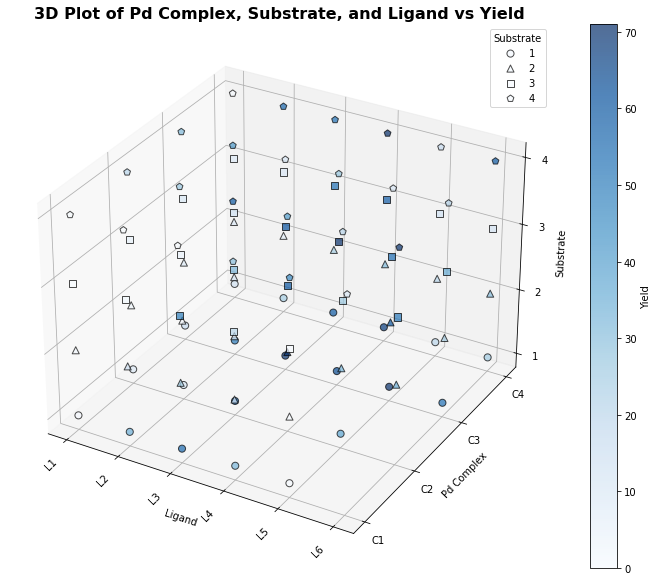

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.colors as mcolors
import numpy as np

# Load the Excel file
file_path = 'Pd_HTE.xlsx'  # Adjust to your file path
df = pd.read_excel(file_path)

# Ensure the structure of the DataFrame is as expected
print(df.head())
print(df.columns)

# Convert Pd Complex, Substrate, and Ligand to string to avoid type issues
df['Pd Complex'] = df['Pd Complex'].astype(str)
df['Substrate'] = df['Substrate'].astype(str)
df['Ligand'] = df['Ligand'].astype(str)

# Create a figure for the 3D plot
fig = plt.figure(figsize=(14, 10))
ax = fig.add_subplot(111, projection='3d')

# Create a mapping for Pd Complex, Substrate, and Ligand to integers for 3D plotting
pd_complex_labels = {label: idx for idx, label in enumerate(df['Pd Complex'].unique())}
substrate_labels = {label: idx for idx, label in enumerate(df['Substrate'].unique())}
ligand_labels = {label: idx for idx, label in enumerate(df['Ligand'].unique())}

# Map the data in the DataFrame to integers
df['Pd Complex ID'] = df['Pd Complex'].map(pd_complex_labels)
df['Substrate ID'] = df['Substrate'].map(substrate_labels)
df['Ligand ID'] = df['Ligand'].map(ligand_labels)

# Define unique markers for each substrate
substrate_markers = ['o', '^', 's', 'p', '*', 'D']  # You can add more shapes if needed

# Plotting 3D scatter plot
# Initialize the scatter plot for each unique Substrate
for substrate, marker in zip(df['Substrate'].unique(), substrate_markers):
    # Filter the DataFrame for each substrate
    subset_df = df[df['Substrate'] == substrate]
    
    # Plotting each subset with the specific marker
    scatter = ax.scatter(
        subset_df['Ligand ID'], subset_df['Pd Complex ID'], subset_df['Substrate ID'],
        c=subset_df['Yield'], cmap='Blues', s=50, edgecolors='k', marker=marker, label=substrate, alpha=0.7
    )

# Labels and title
ax.set_xlabel('Ligand')
ax.set_ylabel('Pd Complex')
ax.set_zlabel('Substrate')

# Set the ticks for each axis based on the original labels
ax.set_xticks(list(ligand_labels.values()))
ax.set_xticklabels(list(ligand_labels.keys()), rotation=45, ha='right', fontsize=10)
ax.set_yticks(list(pd_complex_labels.values()))
ax.set_yticklabels(list(pd_complex_labels.keys()), fontsize=10)
ax.set_zticks(list(substrate_labels.values()))
ax.set_zticklabels(list(substrate_labels.keys()), fontsize=10)

# Add color bar to show the Yield values
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Yield')

# Add a legend for Substrates
ax.legend(title='Substrate')

# Set title and display
ax.set_title('3D Plot of Pd Complex, Substrate, and Ligand vs Yield', fontsize=16, weight='bold')
plt.tight_layout()
plt.show()


First few rows of the DataFrame:
  Ligand Pd Complex  Yield  Substrate
0     L1         C1    9.0          1
1     L2         C1   47.0          1
2     L3         C1   70.0          1
3     L4         C1   45.0          1
4     L5         C1    8.0          1
Columns in the DataFrame: Index(['Ligand', 'Pd Complex', 'Yield', 'Substrate'], dtype='object')
All required columns are present.
Checking for missing or NaN values in essential columns:
Pd Complex ID    0
Ligand ID        0
Substrate ID     0
Yield            0
dtype: int64


/tmp/ipykernel_477839/1852291330.py:37: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['Pd Complex ID'] = df_filtered['Pd Complex'].map(pd_complex_labels)
/tmp/ipykernel_477839/1852291330.py:38: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['Ligand ID'] = df_filtered['Ligand'].map(ligand_labels)
/tmp/ipykernel_477839/1852291330.py:42: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See

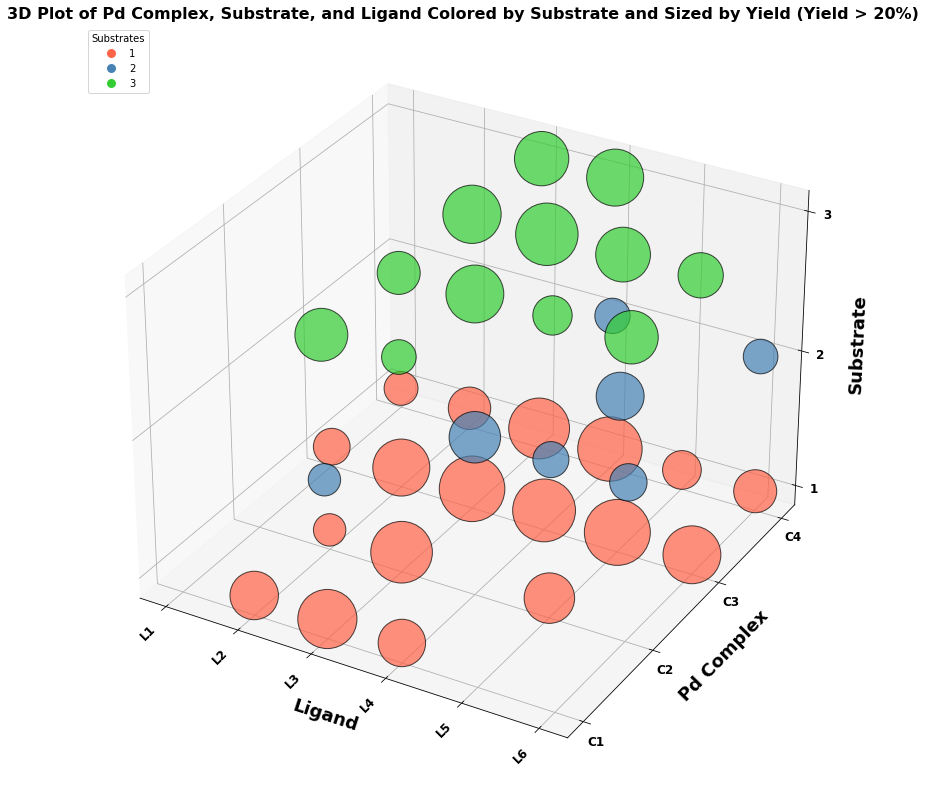

Plot has been saved as 3d_plot_palladium_yield_gt_20.png


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.colors as mcolors

# Load the Excel file
file_path = 'Pd_HTE_1.xlsx'  # Adjust to your file path
df = pd.read_excel(file_path)

# Check if the DataFrame is loaded correctly
print("First few rows of the DataFrame:")
print(df.head())
print("Columns in the DataFrame:", df.columns)

# Ensure that 'Pd Complex', 'Substrate', 'Ligand', and 'Yield' columns exist
if not all(col in df.columns for col in ['Pd Complex', 'Substrate', 'Ligand', 'Yield']):
    print("Error: One or more required columns are missing.")
else:
    print("All required columns are present.")

# Convert 'Pd Complex', 'Substrate', and 'Ligand' to string to avoid type issues
df['Pd Complex'] = df['Pd Complex'].astype(str)
df['Substrate'] = df['Substrate'].astype(str)
df['Ligand'] = df['Ligand'].astype(str)

# Filter the DataFrame to only include rows with Yield > 20%
df_filtered = df[df['Yield'] > 20]

# Sort the 'Ligand' values in sequence (L1, L2, ..., L6)
ligand_order = sorted(df_filtered['Ligand'].unique(), key=lambda x: int(x[1:]))  # Sort based on the number part of the ligand (L1, L2, ...)

# Create a mapping for Pd Complex, Substrate, and Ligand to integers for 3D plotting
pd_complex_labels = {label: idx for idx, label in enumerate(df_filtered['Pd Complex'].unique())}
ligand_labels = {label: idx for idx, label in enumerate(ligand_order)}  # Use sorted ligand order for mapping

# Map the data in the DataFrame to integers
df_filtered['Pd Complex ID'] = df_filtered['Pd Complex'].map(pd_complex_labels)
df_filtered['Ligand ID'] = df_filtered['Ligand'].map(ligand_labels)

# Create a mapping for Substrates to numeric values
substrate_labels = {substrate: idx for idx, substrate in enumerate(df_filtered['Substrate'].unique())}
df_filtered['Substrate ID'] = df_filtered['Substrate'].map(substrate_labels)

# Define a color map for the Substrates (you can adjust the colors if needed)
substrate_colors = ['#FF6347', '#4682B4', '#32CD32']  # Three different colors for substrates
substrate_color_mapping = {substrate: color for substrate, color in zip(df_filtered['Substrate'].unique(), substrate_colors)}

# Map substrates to colors
df_filtered['Substrate Color'] = df_filtered['Substrate'].map(substrate_color_mapping)

# Check for empty or missing values in important columns
print("Checking for missing or NaN values in essential columns:")
print(df_filtered[['Pd Complex ID', 'Ligand ID', 'Substrate ID', 'Yield']].isnull().sum())

# Scale Yield to be used as the size of the points
# We multiply by a constant (e.g., 50) to make the differences in Yield more apparent in the plot
size_scaling_factor = 50
df_filtered['Size'] = df_filtered['Yield'] * size_scaling_factor

# Create a figure for the 3D plot
fig = plt.figure(figsize=(18, 14))
ax = fig.add_subplot(111, projection='3d')

# Plotting 3D scatter plot
scatter = ax.scatter(df_filtered['Ligand ID'], df_filtered['Pd Complex ID'], df_filtered['Substrate ID'],
                     c=df_filtered['Substrate Color'], s=df_filtered['Size'], edgecolors='k', alpha=0.7)

# Labels and title with increased font size and bold text
ax.set_xlabel('Ligand', fontsize=18, fontweight='bold', labelpad=14)  # Adjust labelpad for x-axis
ax.set_ylabel('Pd Complex', fontsize=18, fontweight='bold', labelpad=14)  # Adjust labelpad for y-axis
ax.set_zlabel('Substrate', fontsize=18, fontweight='bold', labelpad=14)  # Adjust labelpad for z-axis

# Set the ticks for each axis based on the original labels
ax.set_xticks(list(ligand_labels.values()))
ax.set_xticklabels(list(ligand_labels.keys()), rotation=45, ha='right', fontsize=12, fontweight='bold')  # Bold the tick labels
ax.set_yticks(list(pd_complex_labels.values()))
ax.set_yticklabels(list(pd_complex_labels.keys()), fontsize=12, fontweight='bold')  # Bold the tick labels
ax.set_zticks(list(substrate_labels.values()))
ax.set_zticklabels(list(substrate_labels.keys()), fontsize=12, fontweight='bold')  # Bold the tick labels

# Create a custom legend for substrates based on color
import matplotlib.lines as mlines
handles = [mlines.Line2D([0], [0], marker='o', color='w', markerfacecolor=color, markersize=10)
           for color in substrate_colors]
ax.legend(handles, list(substrate_labels.keys()), title='Substrates', loc='upper left')

# Set title with bold and larger font size
ax.set_title('3D Plot of Pd Complex, Substrate, and Ligand Colored by Substrate and Sized by Yield (Yield > 20%)', fontsize=16, weight='bold')

# Save the plot as an image (e.g., PNG format)
plt.tight_layout()

# Save the image (adjust the path or format if needed)
output_image = '3d_plot_palladium_yield_gt_20.png'
plt.savefig(output_image, dpi=300)

# Show the plot (optional for interactive sessions)
plt.show()

# Confirm image was saved
print(f"Plot has been saved as {output_image}")


First few rows of the DataFrame:
  Ligand Pd Complex  Yield  Substrate
0     L1         C1    9.0          1
1     L2         C1   47.0          1
2     L3         C1   70.0          1
3     L4         C1   45.0          1
4     L5         C1    8.0          1
Columns in the DataFrame: Index(['Ligand', 'Pd Complex', 'Yield', 'Substrate'], dtype='object')
All required columns are present.
Checking for missing or NaN values in essential columns:
Pd Complex ID    0
Ligand ID        0
Substrate ID     0
Yield            0
dtype: int64


/tmp/ipykernel_477839/53890108.py:37: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['Pd Complex ID'] = df_filtered['Pd Complex'].map(pd_complex_labels)
/tmp/ipykernel_477839/53890108.py:38: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['Ligand ID'] = df_filtered['Ligand'].map(ligand_labels)
/tmp/ipykernel_477839/53890108.py:42: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the c

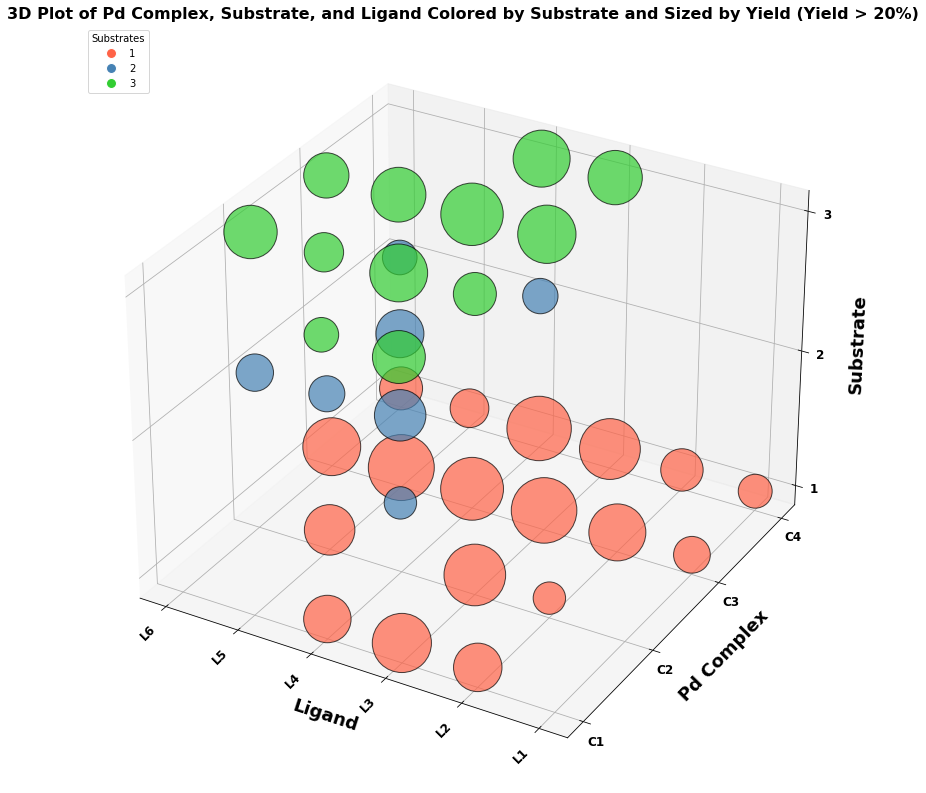

Plot has been saved as 3d_plot_palladium_yield_gt_20_l6_to_l1.png


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.colors as mcolors

# Load the Excel file
file_path = 'Pd_HTE_1.xlsx'  # Adjust to your file path
df = pd.read_excel(file_path)

# Check if the DataFrame is loaded correctly
print("First few rows of the DataFrame:")
print(df.head())
print("Columns in the DataFrame:", df.columns)

# Ensure that 'Pd Complex', 'Substrate', 'Ligand', and 'Yield' columns exist
if not all(col in df.columns for col in ['Pd Complex', 'Substrate', 'Ligand', 'Yield']):
    print("Error: One or more required columns are missing.")
else:
    print("All required columns are present.")

# Convert 'Pd Complex', 'Substrate', and 'Ligand' to string to avoid type issues
df['Pd Complex'] = df['Pd Complex'].astype(str)
df['Substrate'] = df['Substrate'].astype(str)
df['Ligand'] = df['Ligand'].astype(str)

# Filter the DataFrame to only include rows with Yield > 20%
df_filtered = df[df['Yield'] > 20]

# Sort the 'Ligand' values in descending order (L6 to L1)
ligand_order = sorted(df_filtered['Ligand'].unique(), key=lambda x: int(x[1:]), reverse=True)  # Sort based on the number part of the ligand (L6, L5, ...)

# Create a mapping for Pd Complex, Substrate, and Ligand to integers for 3D plotting
pd_complex_labels = {label: idx for idx, label in enumerate(df_filtered['Pd Complex'].unique())}
ligand_labels = {label: idx for idx, label in enumerate(ligand_order)}  # Use sorted ligand order for mapping

# Map the data in the DataFrame to integers
df_filtered['Pd Complex ID'] = df_filtered['Pd Complex'].map(pd_complex_labels)
df_filtered['Ligand ID'] = df_filtered['Ligand'].map(ligand_labels)

# Create a mapping for Substrates to numeric values
substrate_labels = {substrate: idx for idx, substrate in enumerate(df_filtered['Substrate'].unique())}
df_filtered['Substrate ID'] = df_filtered['Substrate'].map(substrate_labels)

# Define a color map for the Substrates (you can adjust the colors if needed)
substrate_colors = ['#FF6347', '#4682B4', '#32CD32']  # Three different colors for substrates
substrate_color_mapping = {substrate: color for substrate, color in zip(df_filtered['Substrate'].unique(), substrate_colors)}

# Map substrates to colors
df_filtered['Substrate Color'] = df_filtered['Substrate'].map(substrate_color_mapping)

# Check for empty or missing values in important columns
print("Checking for missing or NaN values in essential columns:")
print(df_filtered[['Pd Complex ID', 'Ligand ID', 'Substrate ID', 'Yield']].isnull().sum())

# Scale Yield to be used as the size of the points
# We multiply by a constant (e.g., 50) to make the differences in Yield more apparent in the plot
size_scaling_factor = 50
df_filtered['Size'] = df_filtered['Yield'] * size_scaling_factor

# Create a figure for the 3D plot
fig = plt.figure(figsize=(18, 14))
ax = fig.add_subplot(111, projection='3d')

# Plotting 3D scatter plot
scatter = ax.scatter(df_filtered['Ligand ID'], df_filtered['Pd Complex ID'], df_filtered['Substrate ID'],
                     c=df_filtered['Substrate Color'], s=df_filtered['Size'], edgecolors='k', alpha=0.7)

# Labels and title with increased font size and bold text
ax.set_xlabel('Ligand', fontsize=18, fontweight='bold', labelpad=14)  # Adjust labelpad for x-axis
ax.set_ylabel('Pd Complex', fontsize=18, fontweight='bold', labelpad=14)  # Adjust labelpad for y-axis
ax.set_zlabel('Substrate', fontsize=18, fontweight='bold', labelpad=14)  # Adjust labelpad for z-axis

# Set the ticks for each axis based on the original labels
ax.set_xticks(list(ligand_labels.values()))
ax.set_xticklabels(list(ligand_labels.keys()), rotation=45, ha='right', fontsize=12, fontweight='bold')  # Bold the tick labels
ax.set_yticks(list(pd_complex_labels.values()))
ax.set_yticklabels(list(pd_complex_labels.keys()), fontsize=12, fontweight='bold')  # Bold the tick labels
ax.set_zticks(list(substrate_labels.values()))
ax.set_zticklabels(list(substrate_labels.keys()), fontsize=12, fontweight='bold')  # Bold the tick labels

# Create a custom legend for substrates based on color
import matplotlib.lines as mlines
handles = [mlines.Line2D([0], [0], marker='o', color='w', markerfacecolor=color, markersize=10)
           for color in substrate_colors]
ax.legend(handles, list(substrate_labels.keys()), title='Substrates', loc='upper left')

# Set title with bold and larger font size
ax.set_title('3D Plot of Pd Complex, Substrate, and Ligand Colored by Substrate and Sized by Yield (Yield > 20%)', fontsize=16, weight='bold')

# Save the plot as an image (e.g., PNG format)
plt.tight_layout()

# Save the image (adjust the path or format if needed)
output_image = '3d_plot_palladium_yield_gt_20_l6_to_l1.png'
plt.savefig(output_image, dpi=300)

# Show the plot (optional for interactive sessions)
plt.show()

# Confirm image was saved
print(f"Plot has been saved as {output_image}")


First few rows of the DataFrame:
  Ligand Pd Complex  Yield  Substrate
0     L1         C1    9.0          1
1     L2         C1   47.0          1
2     L3         C1   70.0          1
3     L4         C1   45.0          1
4     L5         C1    8.0          1
Columns in the DataFrame: Index(['Ligand', 'Pd Complex', 'Yield', 'Substrate'], dtype='object')
All required columns are present.
Checking for missing or NaN values in essential columns:
Pd Complex ID    0
Ligand ID        0
Substrate ID     0
Yield            0
dtype: int64


/tmp/ipykernel_477839/2127776654.py:113: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


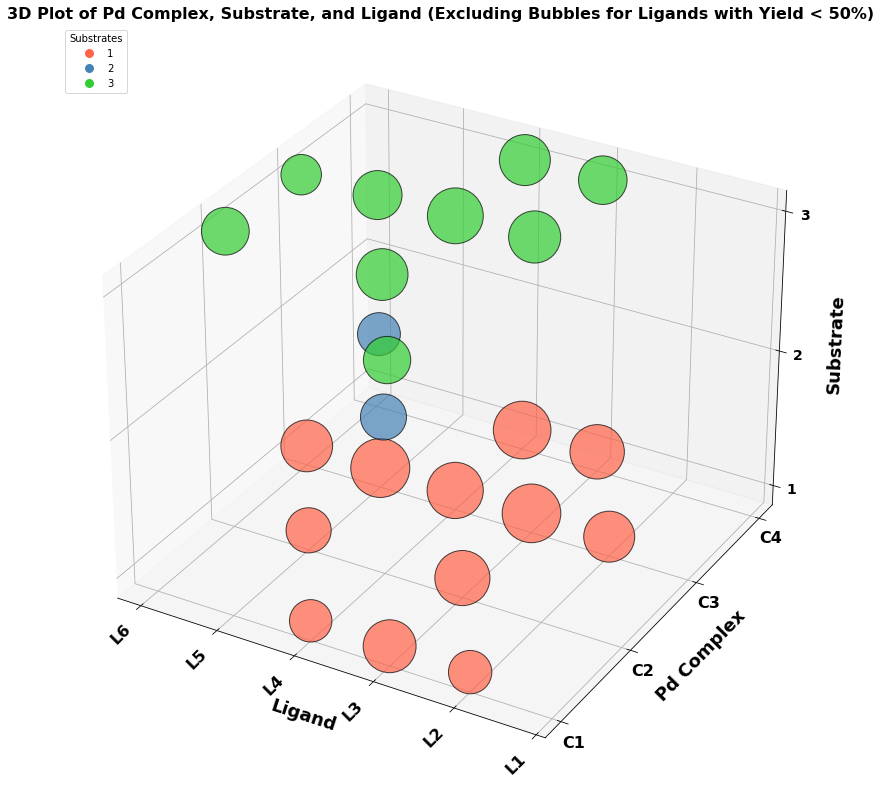

Plot has been saved as 3d_plot_excluding_bubbles_for_low_yield.png


In [25]:
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.colors as mcolors

# Load the Excel file
file_path = 'Pd_HTE_1.xlsx'  # Adjust to your file path
df = pd.read_excel(file_path)

# Check if the DataFrame is loaded correctly
print("First few rows of the DataFrame:")
print(df.head())
print("Columns in the DataFrame:", df.columns)

# Ensure that 'Pd Complex', 'Substrate', 'Ligand', and 'Yield' columns exist
if not all(col in df.columns for col in ['Pd Complex', 'Substrate', 'Ligand', 'Yield']):
    print("Error: One or more required columns are missing.")
else:
    print("All required columns are present.")

# Convert 'Pd Complex', 'Substrate', and 'Ligand' to string to avoid type issues
df['Pd Complex'] = df['Pd Complex'].astype(str)
df['Substrate'] = df['Substrate'].astype(str)
df['Ligand'] = df['Ligand'].astype(str)

# Filter the DataFrame to only include rows with Yield >= 50%
df_filtered = df[df['Yield'] >= 40].copy()  # Make sure we are working with a copy

# Sort the 'Ligand' values in descending order (L6 to L1)
ligand_order = sorted(df['Ligand'].unique(), key=lambda x: int(x[1:]), reverse=True)  # Sort based on the number part of the ligand (L6, L5, ...)

# Create a mapping for Pd Complex, Substrate, and Ligand to integers for 3D plotting
pd_complex_labels = {label: idx for idx, label in enumerate(df['Pd Complex'].unique())}
ligand_labels = {label: idx for idx, label in enumerate(ligand_order)}  # Use sorted ligand order for mapping

# Map the data in the DataFrame to integers for the filtered DataFrame
df_filtered['Pd Complex ID'] = df_filtered['Pd Complex'].map(pd_complex_labels)
df_filtered['Ligand ID'] = df_filtered['Ligand'].map(ligand_labels)

# Create a mapping for Substrates to numeric values
substrate_labels = {substrate: idx for idx, substrate in enumerate(df_filtered['Substrate'].unique())}
df_filtered['Substrate ID'] = df_filtered['Substrate'].map(substrate_labels)

# Define a color map for the Substrates (you can adjust the colors if needed)
substrate_colors = ['#FF6347', '#4682B4', '#32CD32']  # Three different colors for substrates
substrate_color_mapping = {substrate: color for substrate, color in zip(df_filtered['Substrate'].unique(), substrate_colors)}

# Map substrates to colors
df_filtered['Substrate Color'] = df_filtered['Substrate'].map(substrate_color_mapping)

# Check for empty or missing values in important columns
print("Checking for missing or NaN values in essential columns:")
print(df_filtered[['Pd Complex ID', 'Ligand ID', 'Substrate ID', 'Yield']].isnull().sum())

# Scale Yield to be used as the size of the points
# We multiply by a constant (e.g., 50) to make the differences in Yield more apparent in the plot
size_scaling_factor = 40
df_filtered.loc[:, 'Size'] = df_filtered['Yield'] * size_scaling_factor  # Use .loc to avoid SettingWithCopyWarning

# Create a figure for the 3D plot
fig = plt.figure(figsize=(18, 14))
ax = fig.add_subplot(111, projection='3d')

# Plotting 3D scatter plot for top performers (Yield >= 50%)
# Exclude bubbles for ligands with yield < 50%
scatter = ax.scatter(df_filtered['Ligand ID'], df_filtered['Pd Complex ID'], df_filtered['Substrate ID'],
                     c=df_filtered['Substrate Color'], s=df_filtered['Size'], edgecolors='k', alpha=0.7)

# Labels and title with increased font size and bold text
ax.set_xlabel('Ligand', fontsize=18, fontweight='bold', labelpad=14)  # Adjust labelpad for x-axis
ax.set_ylabel('Pd Complex', fontsize=18, fontweight='bold', labelpad=14)  # Adjust labelpad for y-axis
ax.set_zlabel('Substrate', fontsize=18, fontweight='bold', labelpad=14)  # Adjust labelpad for z-axis

# Set the ticks for each axis based on the original labels
# Include all Ligand labels on x-axis, even if their yield is less than 50% (no bubbles for those)
ligand_tick_labels = [ligand for ligand in ligand_labels.keys()]
ligand_tick_values = [ligand_labels[ligand] for ligand in ligand_tick_labels]

ax.set_xticks(ligand_tick_values)
ax.set_xticklabels(ligand_tick_labels, rotation=45, ha='right', fontsize=14, fontweight='bold')  # Bold the tick labels

# Increase label size for L1 to L6
for label in ligand_labels.keys():
    if label.startswith('L'):
        ax.set_xticklabels(ligand_tick_labels, fontsize=16)  # Increase fontsize for Ligand labels (L1 to L6)

ax.set_yticks(list(pd_complex_labels.values()))
ax.set_yticklabels(list(pd_complex_labels.keys()), fontsize=14, fontweight='bold')  # Bold the tick labels

# Increase label size for C1 to C4
for label in pd_complex_labels.keys():
    if label.startswith('C'):
        ax.set_yticklabels(list(pd_complex_labels.keys()), fontsize=16)  # Increase fontsize for Pd Complex labels (C1 to C4)

ax.set_zticks(list(substrate_labels.values()))
ax.set_zticklabels(list(substrate_labels.keys()), fontsize=14, fontweight='bold')  # Bold the tick labels

# Increase label size for Substrate 1, 2, and 3
for label in substrate_labels.keys():
    if label.startswith('Substrate'):
        ax.set_zticklabels(list(substrate_labels.keys()), fontsize=16)  # Increase fontsize for Substrate labels

# Create a custom legend for substrates based on color
import matplotlib.lines as mlines
handles = [mlines.Line2D([0], [0], marker='o', color='w', markerfacecolor=color, markersize=10)
           for color in substrate_colors]
ax.legend(handles, list(substrate_labels.keys()), title='Substrates', loc='upper left')

# Set title with bold and larger font size
ax.set_title('3D Plot of Pd Complex, Substrate, and Ligand (Excluding Bubbles for Ligands with Yield < 50%)', fontsize=16, weight='bold')

# Save the plot as an image (e.g., PNG format)
plt.tight_layout()

# Save the image (adjust the path or format if needed)
output_image = '3d_plot_excluding_bubbles_for_low_yield.png'
plt.savefig(output_image, dpi=300)

# Show the plot (optional for interactive sessions)
plt.show()

# Confirm image was saved
print(f"Plot has been saved as {output_image}")


First few rows of the DataFrame:
  Ligand Pd Complex  Substrate  Yield
0     L1         C1          1      9
1     L2         C1          1     47
2     L3         C1          1     60
3     L4         C1          1     45
4     L5         C1          1      8
Columns in the DataFrame: Index(['Ligand', 'Pd Complex', 'Substrate', 'Yield'], dtype='object')
All required columns are present.
Checking for missing or NaN values in essential columns:
Pd Complex ID    0
Ligand ID        0
Substrate ID     0
Yield            0
dtype: int64


/tmp/ipykernel_477839/2262192757.py:103: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


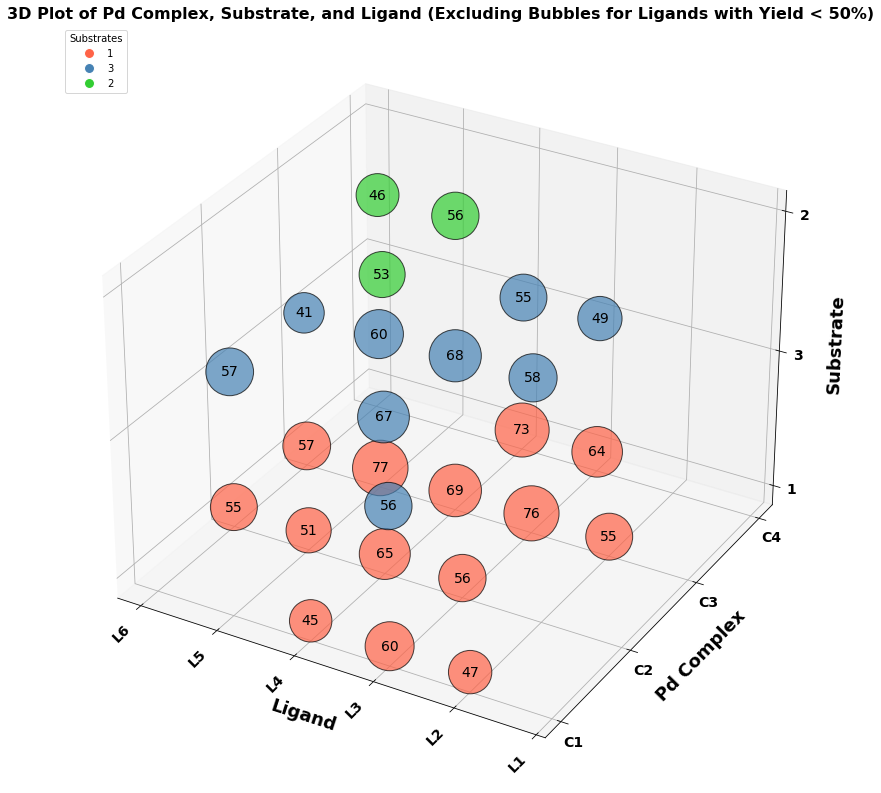

Plot has been saved as 3d_plot_excluding_bubbles_for_low_yield_with_integer_yield_values.png


In [31]:
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.colors as mcolors

# Load the Excel file
file_path = 'Pd_HTE_1.xlsx'  # Adjust to your file path
df = pd.read_excel(file_path)

# Check if the DataFrame is loaded correctly
print("First few rows of the DataFrame:")
print(df.head())
print("Columns in the DataFrame:", df.columns)

# Ensure that 'Pd Complex', 'Substrate', 'Ligand', and 'Yield' columns exist
if not all(col in df.columns for col in ['Pd Complex', 'Substrate', 'Ligand', 'Yield']):
    print("Error: One or more required columns are missing.")
else:
    print("All required columns are present.")

# Convert 'Pd Complex', 'Substrate', and 'Ligand' to string to avoid type issues
df['Pd Complex'] = df['Pd Complex'].astype(str)
df['Substrate'] = df['Substrate'].astype(str)
df['Ligand'] = df['Ligand'].astype(str)

# Filter the DataFrame to only include rows with Yield >= 50%
df_filtered = df[df['Yield'] >= 40].copy()  # Make sure we are working with a copy

# Sort the 'Ligand' values in descending order (L6 to L1)
ligand_order = sorted(df['Ligand'].unique(), key=lambda x: int(x[1:]), reverse=True)  # Sort based on the number part of the ligand (L6, L5, ...)

# Create a mapping for Pd Complex, Substrate, and Ligand to integers for 3D plotting
pd_complex_labels = {label: idx for idx, label in enumerate(df['Pd Complex'].unique())}
ligand_labels = {label: idx for idx, label in enumerate(ligand_order)}  # Use sorted ligand order for mapping

# Map the data in the DataFrame to integers for the filtered DataFrame
df_filtered['Pd Complex ID'] = df_filtered['Pd Complex'].map(pd_complex_labels)
df_filtered['Ligand ID'] = df_filtered['Ligand'].map(ligand_labels)

# Create a mapping for Substrates to numeric values
substrate_labels = {substrate: idx for idx, substrate in enumerate(df_filtered['Substrate'].unique())}
df_filtered['Substrate ID'] = df_filtered['Substrate'].map(substrate_labels)

# Define a color map for the Substrates (you can adjust the colors if needed)
substrate_colors = ['#FF6347', '#4682B4', '#32CD32']  # Three different colors for substrates
substrate_color_mapping = {substrate: color for substrate, color in zip(df_filtered['Substrate'].unique(), substrate_colors)}

# Map substrates to colors
df_filtered['Substrate Color'] = df_filtered['Substrate'].map(substrate_color_mapping)

# Check for empty or missing values in important columns
print("Checking for missing or NaN values in essential columns:")
print(df_filtered[['Pd Complex ID', 'Ligand ID', 'Substrate ID', 'Yield']].isnull().sum())

# Scale Yield to be used as the size of the points
# We multiply by a constant (e.g., 50) to make the differences in Yield more apparent in the plot
size_scaling_factor = 40
df_filtered.loc[:, 'Size'] = df_filtered['Yield'] * size_scaling_factor  # Use .loc to avoid SettingWithCopyWarning

# Create a figure for the 3D plot
fig = plt.figure(figsize=(18, 14))
ax = fig.add_subplot(111, projection='3d')

# Plotting 3D scatter plot for top performers (Yield >= 50%)
# Exclude bubbles for ligands with yield < 50%
scatter = ax.scatter(df_filtered['Ligand ID'], df_filtered['Pd Complex ID'], df_filtered['Substrate ID'],
                     c=df_filtered['Substrate Color'], s=df_filtered['Size'], edgecolors='k', alpha=0.7)

# Labels and title with increased font size and bold text
ax.set_xlabel('Ligand', fontsize=18, fontweight='bold', labelpad=14)  # Adjust labelpad for x-axis
ax.set_ylabel('Pd Complex', fontsize=18, fontweight='bold', labelpad=14)  # Adjust labelpad for y-axis
ax.set_zlabel('Substrate', fontsize=18, fontweight='bold', labelpad=14)  # Adjust labelpad for z-axis

# Set the ticks for each axis based on the original labels
# Include all Ligand labels on x-axis, even if their yield is less than 50% (no bubbles for those)
ligand_tick_labels = [ligand for ligand in ligand_labels.keys()]
ligand_tick_values = [ligand_labels[ligand] for ligand in ligand_tick_labels]

ax.set_xticks(ligand_tick_values)
ax.set_xticklabels(ligand_tick_labels, rotation=45, ha='right', fontsize=14, fontweight='bold')  # Bold the tick labels

ax.set_yticks(list(pd_complex_labels.values()))
ax.set_yticklabels(list(pd_complex_labels.keys()), fontsize=14, fontweight='bold')  # Bold the tick labels

ax.set_zticks(list(substrate_labels.values()))
ax.set_zticklabels(list(substrate_labels.keys()), fontsize=14, fontweight='bold')  # Bold the tick labels

# Create a custom legend for substrates based on color
import matplotlib.lines as mlines
handles = [mlines.Line2D([0], [0], marker='o', color='w', markerfacecolor=color, markersize=10)
           for color in substrate_colors]
ax.legend(handles, list(substrate_labels.keys()), title='Substrates', loc='upper left')

# Set title with bold and larger font size
ax.set_title('3D Plot of Pd Complex, Substrate, and Ligand (Excluding Bubbles for Ligands with Yield < 50%)', fontsize=16, weight='bold')

# Display Yield values as integers inside bubbles (without percentage and decimals)
for i, row in df_filtered.iterrows():
    ax.text(row['Ligand ID'], row['Pd Complex ID'], row['Substrate ID'],
            f"{int(row['Yield'])}", color='black', fontsize=14, ha='center', va='center')

# Save the plot as an image (e.g., PNG format)
plt.tight_layout()

# Save the image (adjust the path or format if needed)
output_image = '3d_plot_excluding_bubbles_for_low_yield_with_integer_yield_values.png'
plt.savefig(output_image, dpi=300)

# Show the plot (optional for interactive sessions)
plt.show()

# Confirm image was saved
print(f"Plot has been saved as {output_image}")
